In [1]:
import contextlib, io
import numpy as np
import matplotlib.pyplot as plt
from pylblrtm import from_hapi, us_standard_atmosphere, compute_transmittance

with contextlib.redirect_stdout(io.StringIO()):
    sd = from_hapi("CO2", 675, 775)
perfil = us_standard_atmosphere(gases=["CO2"])
compute_transmittance(sd, perfil, 730, 730.01, voigt="humlicek", wing_tolerance=1e-4);

In [2]:
%%time
nu, T_wofz = compute_transmittance(sd, perfil, 730, 750)

CPU times: total: 1min 50s
Wall time: 1min 49s


In [3]:
%%time
nu, T_humlicek = compute_transmittance(sd, perfil, 730, 750, voigt="humlicek")

CPU times: total: 1.23 s
Wall time: 1.26 s


In [4]:
%%time
nu, T_njobs = compute_transmittance(sd, perfil, 730, 750, voigt="humlicek", n_jobs=-1)

CPU times: total: 2.14 s
Wall time: 305 ms


In [5]:
%%time
nu, T_tol = compute_transmittance(sd, perfil, 730, 750, voigt="humlicek", n_jobs=-1, wing_tolerance=1e-4)

CPU times: total: 453 ms
Wall time: 67.8 ms


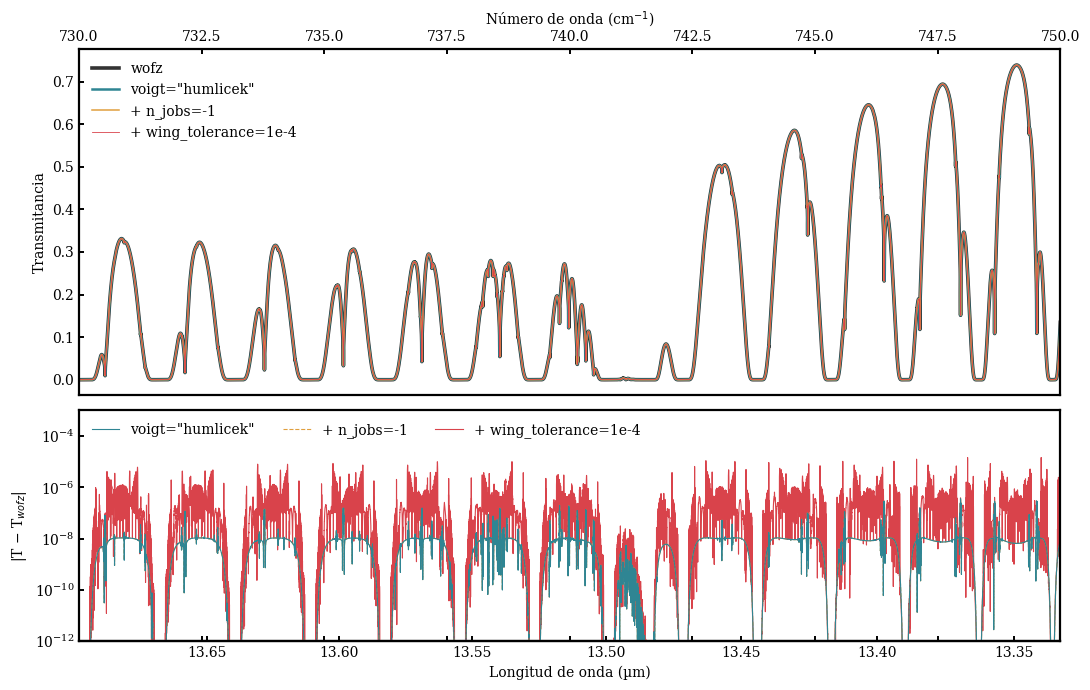

In [6]:
plt.rcParams.update({"font.family": "serif", "axes.linewidth": 1.6, "xtick.major.width": 1.4,
                     "ytick.major.width": 1.4, "xtick.direction": "in", "ytick.direction": "in"})
casos = [("wofz", T_wofz, "0.2", 2.6),
         ('voigt="humlicek"', T_humlicek, "#2F8593", 1.8),
         ("+ n_jobs=-1", T_njobs, "#E09F3E", 1.1),
         ("+ wing_tolerance=1e-4", T_tol, "#D9434B", 0.6)]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, height_ratios=[3, 2])
for nombre, T, color, lw in casos:
    a1.plot(nu, T, color=color, lw=lw, label=nombre)
for nombre, T, color, lw in casos[:0:-1]:
    a2.semilogy(nu, np.abs(T - T_wofz), color=color, lw=0.8, ls="--" if "n_jobs" in nombre and "wing" not in nombre else "-",
                label=nombre)
a1.set_ylabel("Transmitancia")
a2.set_ylabel("|T − T$_{wofz}$|")
a2.set_ylim(1e-12, 1e-3)
a1.legend(frameon=False, loc="upper left")
a2.legend(*[x[::-1] for x in a2.get_legend_handles_labels()], frameon=False, loc="upper left", ncol=3)
a1.xaxis.tick_top()
a1.tick_params(labeltop=True)
a1.xaxis.set_label_position("top")
a1.set_xlabel("Número de onda (cm$^{-1}$)")
a2.set_xlim(nu[0], nu[-1])
a2.tick_params(labelbottom=False)
inv = lambda x: 1e4 / np.maximum(x, 1e-6)
lam = a2.secondary_xaxis("bottom", functions=(inv, inv))
lam.set_xlabel("Longitud de onda (µm)")
fig.tight_layout()